# 04 - Décrire les usagers et explorer les différences de gravité

Les trois premiers notebooks ont permis de comprendre les sources, d'auditer les six années
et de construire une table métropolitaine avec une ligne par usager. Nous pouvons maintenant
examiner la population et les différences de gravité qui mériteront une analyse plus approfondie.

**La question de ce notebook : comment la gravité se répartit-elle parmi les usagers enregistrés,
et quelles différences descriptives observe-t-on selon l'âge, la catégorie d'usager, la lumière
et l'agglomération ?**

Le parcours comprend une vérification du chargement, un portrait de la population, une lecture
de la gravité, quatre comparaisons ciblées et un bilan. Chaque graphique répond à une question
et s'accompagne d'un commentaire. Les tableaux donnent les effectifs qui permettent de comprendre
les proportions affichées.


## Périmètre de l'exploration

Le projet porte sur **2019-2024 en France métropolitaine, Corse comprise**. Ce notebook concentre
les explorations qui guideront la modélisation sur **2019-2022**, la période d'apprentissage.
Les données de 2023 restent réservées à la validation et celles de 2024 au test final. Elles ont
déjà été examinées dans les audits de structure ; nous le déclarerons dans le rapport.

La lecture du fichier préparé parcourt ses lignes pour sélectionner les années, puis conserve
uniquement 2019-2022 en mémoire. Aucun tableau de comparaison de gravité ni graphique n'est
calculé sur 2023 ou 2024 dans ce notebook.

**Une ligne représente un usager impliqué dans un accident corporel enregistré**, pas un trajet.
Une proportion élevée de décès ou d'hospitalisations dans un groupe décrit la gravité parmi
ces usagers. Elle ne mesure pas son risque d'avoir un accident par kilomètre ou par déplacement.
Les usagers d'un même accident sont liés ; les méthodes d'incertitude utilisées ensuite devront
tenir compte de cette dépendance.

Les commentaires chiffrés ci-dessous correspondent aux sources du projet examinées le
16 octobre 2026. Ils devront être relus si les données préparées sont remplacées.


In [18]:
from pathlib import Path
import hashlib
import json
import platform
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_colwidth", 75)
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.titlesize": 12, "axes.titleweight": "semibold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.labelcolor": "#263746", "text.color": "#263746",
    "axes.axisbelow": True, "figure.facecolor": "white", "savefig.facecolor": "white",
})
BLUE, ORANGE, GREY = "#285E7E", "#C46B32", "#78868F"
EXPORT_RESULTS = True
TRAIN_YEARS = [2019, 2020, 2021, 2022]
TARGET = "cible_deces_hospitalisation"

print(f"Python {platform.python_version()} | pandas {pd.__version__} | matplotlib {matplotlib.__version__}")


Python 3.12.3 | pandas 3.0.6 | matplotlib 3.11.2


## 1. Charger les données préparées et vérifier leur lecture

Nous utilisons le CSV compressé et le schéma produits par le notebook 03. Le marqueur de valeur
manquante, les types et les codes en texte sont repris explicitement. Aucune décompression manuelle
n'est nécessaire. Les graphiques n'ont pas besoin des 119 colonnes : nous chargeons les variables
utiles à cette exploration, avec les identifiants nécessaires aux contrôles.


In [19]:
PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "processed").is_dir()), None
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Dossier data/processed introuvable. Exécuter le notebook 03 au préalable.")
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
DATA_PATH = PROCESSED_DIR / "baac_usagers_metropole_2019_2024.csv.gz"
SCHEMA_PATH = PROCESSED_DIR / "baac_regles_et_schema.json"
POPULATION_PATH = PROCESSED_DIR / "baac_bilan_effectifs.csv"
for required in [DATA_PATH, SCHEMA_PATH, POPULATION_PATH]:
    if not required.is_file():
        raise FileNotFoundError(f"Fichier nécessaire absent : {required.name}. Relancer le notebook 03.")

schema = json.loads(SCHEMA_PATH.read_text(encoding="utf-8"))
if "marqueur_na_csv" not in schema:
    raise ValueError("Le schéma doit provenir de la version revue du notebook 03, avec marqueur NA explicite.")
COLUMNS = ["id_observation", "Num_Acc", "annee_source", "role_temporel", "dep",
           "catu", "grav", "cible_connue", TARGET, "age_approx", "age_suspect", "age_manquant", "lum", "agg"]
schema_by_name = {entry["nom"]: entry for entry in schema["colonnes"]}
if set(COLUMNS) - set(schema_by_name):
    raise ValueError("Il manque une variable nécessaire dans le schéma préparé.")
dtypes = {col: schema_by_name[col]["dtype"] for col in COLUMNS}

def file_sha256(file_path):
    digest = hashlib.sha256()
    with file_path.open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

input_sha256 = file_sha256(DATA_PATH)
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures"
TABLE_DIR = PROJECT_ROOT / "reports" / "tables"
figure_names = []
if EXPORT_RESULTS:
    FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    TABLE_DIR.mkdir(parents=True, exist_ok=True)


In [20]:
training_parts = []
with pd.read_csv(DATA_PATH, usecols=COLUMNS, dtype=dtypes, keep_default_na=False,
                 na_values=[schema["marqueur_na_csv"]], chunksize=100_000) as reader:
    for chunk in reader:
        selected = chunk.loc[chunk["annee_source"].isin(TRAIN_YEARS)].copy()
        if not selected.empty:
            training_parts.append(selected)
data = pd.concat(training_parts, ignore_index=True)
del training_parts, chunk, selected

assert data["annee_source"].isin(TRAIN_YEARS).all()
assert set(data["annee_source"]) == set(TRAIN_YEARS)
assert data["role_temporel"].eq("apprentissage").all()
assert data["dep"].isin(schema["codes_metropole"]).all()
assert data["id_observation"].notna().all() and data["id_observation"].is_unique
assert data[TARGET].dropna().isin([0, 1]).all()
assert data["cible_connue"].equals(data[TARGET].notna().astype("boolean"))
assert data["age_manquant"].equals(data["age_approx"].isna().astype("boolean"))
assert data["age_approx"].dropna().between(0, 110).all()
assert data[TARGET].equals(data["grav"].map({"1": 0, "2": 1, "3": 1, "4": 0}).astype("Int64"))

previous_population = pd.read_csv(POPULATION_PATH)
previous_train = previous_population.loc[previous_population["année"].isin(TRAIN_YEARS)]
assert len(data) == int(previous_train["usagers_métropole"].sum())
assert int(data[TARGET].isna().sum()) == int(previous_train["cible_inconnue"].sum())

loading_check = pd.Series({
    "usagers_2019_2022": len(data),
    "accidents_distincts": data[["annee_source", "Num_Acc"]].drop_duplicates().shape[0],
    "gravités_connues": int(data[TARGET].notna().sum()),
    "gravités_inconnues": int(data[TARGET].isna().sum()),
    "âges_inconnus_après_préparation": int(data["age_approx"].isna().sum()),
    "âges_suspects_signalés": int(data["age_suspect"].sum()),
}, name="contrôle_du_chargement")
display(loading_check)


usagers_2019_2022                  467348
accidents_distincts                207057
gravités_connues                   467079
gravités_inconnues                    269
âges_inconnus_après_préparation      5818
âges_suspects_signalés                172
Name: contrôle_du_chargement, dtype: int64

Les contrôles retrouvent **467 348 usagers** et **207 057 accidents distincts** sur 2019-2022.
La gravité est inconnue pour 269 usagers ; l'âge préparé manque pour 5 818 personnes, dont
172 signalées pour un âge suspect. Ces usagers restent présents dans le portrait de la population.

Il faut distinguer les niveaux de comptage : quatre personnes dans un même accident représentent
quatre usagers et un seul accident. Les tableaux et graphiques ci-dessous précisent leur unité.


### Trois dénominateurs à ne pas confondre

| Indicateur | Numérateur | Dénominateur |
| --- | --- | --- |
| Part d'une catégorie d'usagers | Usagers de la catégorie | Tous les usagers de la population décrite |
| Part d'une modalité de gravité | Usagers dans cette modalité | Tous les usagers ; les gravités inconnues sont une ligne séparée |
| Proportion de décès ou d'hospitalisations dans un groupe | Usagers du groupe avec cible 1 | Usagers du même groupe dont la cible est connue |

Par exemple, une proportion de 20 % signifie ici 20 décès ou hospitalisations pour 100 usagers
du groupe dont la gravité est connue. La proportion ne comprend pas les gravités inconnues dans
son dénominateur. Nous en affichons donc toujours le nombre à côté.


In [21]:
CATU_LABELS = {"1": "Conducteur", "2": "Passager", "3": "Piéton"}
GRAV_LABELS = {"1": "Indemne", "2": "Tué", "3": "Blessé hospitalisé", "4": "Blessé léger"}
LUM_LABELS = {
    "1": "Plein jour", "2": "Crépuscule ou aube", "3": "Nuit sans éclairage public",
    "4": "Nuit, éclairage public éteint", "5": "Nuit, éclairage public allumé",
}
AGG_LABELS = {"1": "Hors agglomération", "2": "En agglomération"}
MISSING = "Non renseigné"

data["categorie_usager"] = data["catu"].map(CATU_LABELS).fillna(MISSING).astype("string")
data["gravite_libelle"] = data["grav"].map(GRAV_LABELS).fillna(MISSING).astype("string")
data["lumiere"] = data["lum"].map(LUM_LABELS).fillna(MISSING).astype("string")
data["agglomeration"] = data["agg"].map(AGG_LABELS).fillna(MISSING).astype("string")

def describe_groups(frame, group_column, order=None):
    """Séparer effectif total, disponibilité de la cible et proportion parmi les cibles connues."""
    grouped = frame.groupby(group_column, dropna=False, observed=True, sort=False)
    table = grouped.agg(
        usagers_total=("id_observation", "size"),
        cible_connue=("cible_connue", "sum"),
        deces_ou_hospitalisation=(TARGET, "sum"),
    )
    table["cible_inconnue"] = table["usagers_total"] - table["cible_connue"]
    denominator = table["cible_connue"].astype("Float64").mask(table["cible_connue"].eq(0))
    table["proportion_positive_pct"] = 100 * table["deces_ou_hospitalisation"] / denominator
    if order is not None:
        observed_order = [group for group in order if group in table.index]
        remaining = [group for group in table.index if group not in observed_order]
        table = table.reindex(observed_order + remaining)
    return table[["usagers_total", "cible_connue", "cible_inconnue",
                  "deces_ou_hospitalisation", "proportion_positive_pct"]]

def format_integer(value):
    return f"{int(value):,}".replace(",", " ")

def format_percent(value):
    return f"{value:.1f}".replace(".", ",") + " %"

def finish_figure(fig, name):
    if EXPORT_RESULTS:
        fig.savefig(FIGURE_DIR / name, dpi=180, bbox_inches="tight")
        figure_names.append(name)
    display(fig)
    plt.close(fig)

global_rate = 100 * float(data[TARGET].sum()) / int(data[TARGET].notna().sum())


## 2. Décrire la population enregistrée

### Les effectifs d'usagers et d'accidents varient-ils selon l'année ?

Le tableau rassemble les deux unités. Pour compter les accidents, nous utilisons les identifiants
distincts ; pour les usagers, nous comptons les lignes. Les deux courbes sont placées sur des
axes séparés pour éviter de confondre leurs échelles.


,usagers,accidents,cibles_connues,positifs,cibles_inconnues,proportion_positive_pct
annee_source,,,,,,
2019,126352,56016,126352,22853,0,18.09
2020,99169,45121,99169,18141,0,18.29
2021,122189,53540,122135,20796,54,17.03
2022,119638,52380,119423,21291,215,17.83


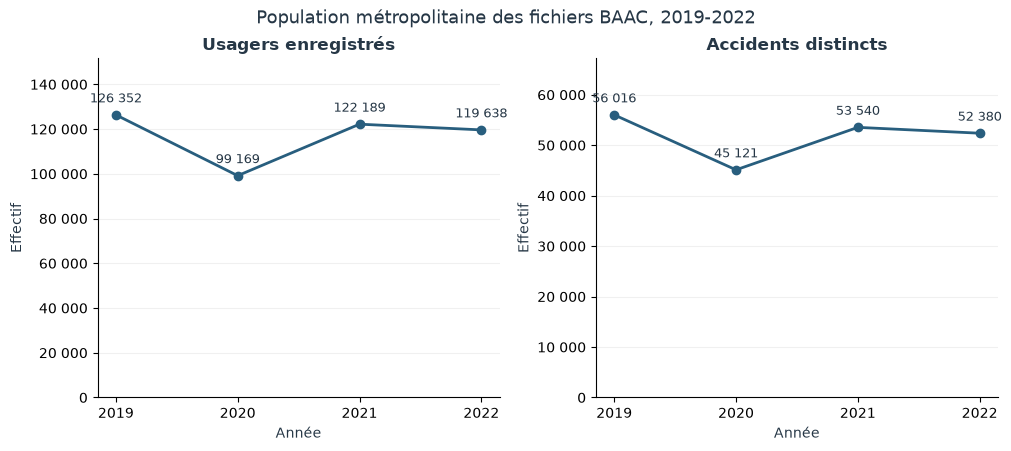

In [22]:
annual_population = data.groupby("annee_source").agg(
    usagers=("id_observation", "size"), accidents=("Num_Acc", "nunique"),
    cibles_connues=("cible_connue", "sum"), positifs=(TARGET, "sum"),
)
annual_population["cibles_inconnues"] = annual_population["usagers"] - annual_population["cibles_connues"]
annual_population["proportion_positive_pct"] = 100 * annual_population["positifs"] / annual_population["cibles_connues"]
display(annual_population.round({"proportion_positive_pct": 2}))

fig, axes = plt.subplots(1, 2, figsize=(10, 4.4), constrained_layout=True)
for ax, col, title in zip(axes, ["usagers", "accidents"], ["Usagers enregistrés", "Accidents distincts"]):
    ax.plot(annual_population.index, annual_population[col], marker="o", color=BLUE, linewidth=2)
    ax.set(title=title, xlabel="Année", ylabel="Effectif")
    ax.set_xticks(TRAIN_YEARS)
    ax.set_ylim(0, annual_population[col].max() * 1.20)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_integer(value)))
    ax.grid(axis="y", alpha=0.18)
    for year, value in annual_population[col].items():
        ax.annotate(format_integer(value), (year, value), xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
fig.suptitle("Population métropolitaine des fichiers BAAC, 2019-2022", fontsize=13)
finish_figure(fig, "04_01_effectifs_annuels.png")


L'année 2020 présente le plus faible effectif : **99 169 usagers**, contre 126 352 en 2019.
Les effectifs remontent ensuite sans retrouver exactement le niveau de 2019 sur cette période.
Le nombre d'accidents suit une évolution comparable.

Ces courbes décrivent des volumes enregistrés. Sans données sur les déplacements, nous ne
pouvons pas en déduire une évolution de la probabilité d'accident par trajet. La différence
entre années invite aussi à conserver une lecture annuelle des comparaisons suivantes.


### Quels âges sont représentés ?

L'histogramme décrit uniquement les âges préparés connus, avec des classes de cinq ans.
Les valeurs manquantes sont comptées à part. Les statistiques portent sur un âge approximatif
calculé à partir des années, pas sur l'âge exact au jour de l'accident.


,âge_approximatif
count,461530.0
mean,38.54
std,18.92
min,0.0
25%,23.0
50%,35.0
75%,52.0
max,110.0


âge_connu               461530.00
âge_inconnu               5818.00
part_âge_inconnu_pct         1.24
dtype: float64

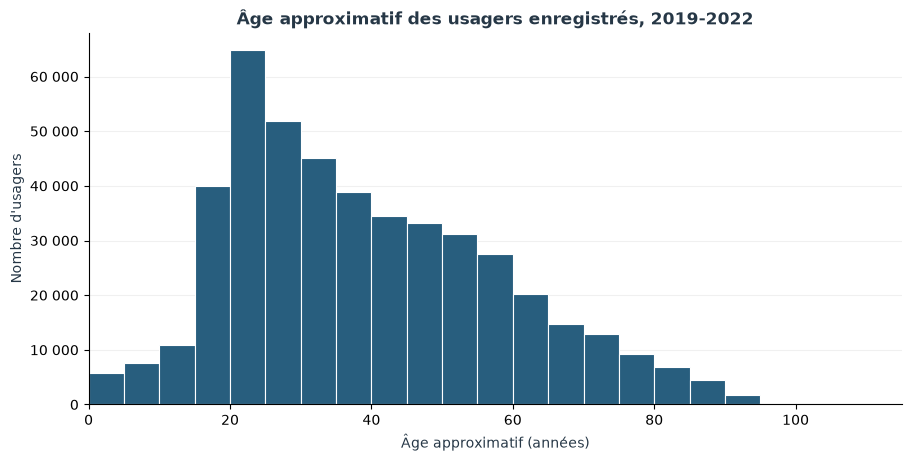

In [23]:
age_summary = data["age_approx"].describe(percentiles=[0.25, 0.5, 0.75]).to_frame("âge_approximatif")
display(age_summary.round(2))
display(pd.Series({"âge_connu": int(data["age_approx"].notna().sum()),
                   "âge_inconnu": int(data["age_approx"].isna().sum()),
                   "part_âge_inconnu_pct": round(100 * data["age_approx"].isna().mean(), 2)}))

fig, ax = plt.subplots(figsize=(9, 4.5), constrained_layout=True)
ax.hist(data["age_approx"].dropna().to_numpy(dtype=float), bins=np.arange(0, 116, 5),
        color=BLUE, edgecolor="white", linewidth=0.8)
ax.set(title="Âge approximatif des usagers enregistrés, 2019-2022",
       xlabel="Âge approximatif (années)", ylabel="Nombre d'usagers", xlim=(0, 115))
ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _: format_integer(value)))
ax.grid(axis="y", alpha=0.18)
finish_figure(fig, "04_02_distribution_age.png")


L'âge médian est de **35 ans** : la moitié des âges connus est inférieure ou égale à cette
valeur. Les premier et troisième quartiles sont de 23 et 52 ans. La moyenne, environ 38,5 ans,
est plus élevée que la médiane.

Les **5 818 âges inconnus**, soit environ 1,2 % des usagers, ne sont pas représentés dans
l'histogramme. Leur répartition de gravité sera conservée dans le tableau de comparaison,
car l'absence d'âge pourrait être liée aux pratiques d'enregistrement.


### Conducteurs, passagers et piétons : quels effectifs ?

`catu` décrit la place de l'usager dans l'accident. Les libellés rendent le graphique plus
lisible que les codes 1, 2 et 3. Pour les piétons, rappelons que le véhicule associé dans BAAC
est celui qui les a heurtés : sa catégorie n'est pas leur propre mode de déplacement.


,usagers,part_des_usagers_pct
catégorie,,
Conducteur,348230,74.51
Passager,82592,17.67
Piéton,36526,7.82


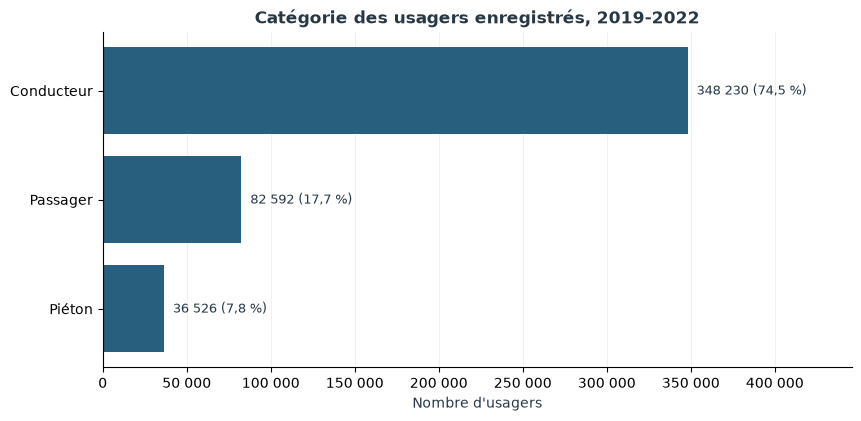

In [24]:
category_order = list(CATU_LABELS.values()) + [MISSING]
category_population = data["categorie_usager"].value_counts().reindex(
    [label for label in category_order if label in data["categorie_usager"].unique()]
).rename_axis("catégorie").to_frame("usagers")
category_population["part_des_usagers_pct"] = 100 * category_population["usagers"] / len(data)
display(category_population.round({"part_des_usagers_pct": 2}))

fig, ax = plt.subplots(figsize=(8.5, 4.1), constrained_layout=True)
bars = ax.barh(category_population.index, category_population["usagers"], color=BLUE)
ax.invert_yaxis()
ax.set(title="Catégorie des usagers enregistrés, 2019-2022", xlabel="Nombre d'usagers")
ax.set_xlim(0, category_population["usagers"].max() * 1.28)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: format_integer(value)))
ax.grid(axis="x", alpha=0.18)
for bar, (_, row) in zip(bars, category_population.iterrows()):
    ax.text(bar.get_width() + category_population["usagers"].max() * 0.015,
            bar.get_y() + bar.get_height()/2,
            f"{format_integer(row['usagers'])} ({format_percent(row['part_des_usagers_pct'])})", va="center", fontsize=9)
finish_figure(fig, "04_03_categories_usagers.png")


Les conducteurs représentent environ **74,5 %** des usagers de cette population, contre
17,7 % de passagers et 7,8 % de piétons. Cette différence d'effectifs rend la comparaison
des seuls nombres de décès ou d'hospitalisations insuffisante pour décrire la gravité
relative des groupes. Nous comparerons leurs proportions parmi les gravités connues.


## 3. Décrire la gravité et le regroupement retenu

### Les quatre modalités de `grav`

Nous conservons les quatre catégories pour voir ce que contient la cible binaire. Les
gravités inconnues apparaissent dans le tableau et le graphique. Les pourcentages de ce
tableau ont pour dénominateur **tous les usagers**, contrairement aux comparaisons de cible
qui suivront.


,usagers,part_des_usagers_pct
gravité,,
Indemne,196270,42.0
Tué,11996,2.57
Blessé hospitalisé,71085,15.21
Blessé léger,187728,40.17
Non renseigné,269,0.06


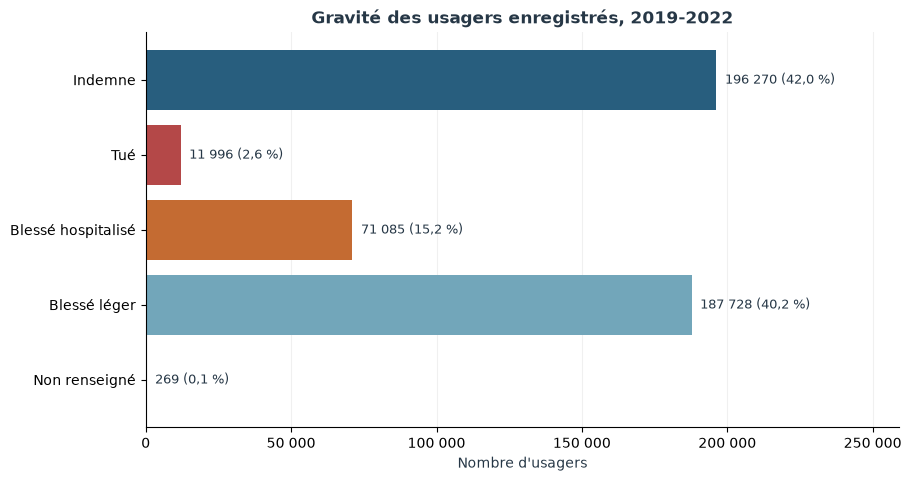

In [25]:
severity_order = list(GRAV_LABELS.values()) + [MISSING]
severity_population = data["gravite_libelle"].value_counts().reindex(severity_order, fill_value=0)
severity_population = severity_population.rename_axis("gravité").to_frame("usagers")
severity_population["part_des_usagers_pct"] = 100 * severity_population["usagers"] / len(data)
display(severity_population.round({"part_des_usagers_pct": 2}))

fig, ax = plt.subplots(figsize=(9, 4.7), constrained_layout=True)
bars = ax.barh(severity_population.index, severity_population["usagers"],
               color=[BLUE, "#B44848", ORANGE, "#72A6BA", GREY])
ax.invert_yaxis()
ax.set(title="Gravité des usagers enregistrés, 2019-2022", xlabel="Nombre d'usagers")
ax.set_xlim(0, severity_population["usagers"].max() * 1.32)
ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: format_integer(value)))
ax.grid(axis="x", alpha=0.18)
for bar, (_, row) in zip(bars, severity_population.iterrows()):
    ax.text(bar.get_width() + severity_population["usagers"].max() * 0.015,
            bar.get_y() + bar.get_height()/2,
            f"{format_integer(row['usagers'])} ({format_percent(row['part_des_usagers_pct'])})", va="center", fontsize=9)
finish_figure(fig, "04_04_repartition_gravite.png")


La population comprend **11 996 personnes tuées** et **71 085 blessés hospitalisés**.
Les indemnes et les blessés légers représentent ensemble la majorité des usagers enregistrés.
Les 269 gravités inconnues restent distinctes ; leur faible nombre total ne garantit pas
qu'elles se répartissent uniformément entre les groupes.

### La cible « décès ou hospitalisation »

La cible regroupe les modalités 2 et 3. Les hospitalisations de plus de 24 heures sont un
indicateur imparfait de la gravité médicale, avec des limites de collecte signalées dans
la documentation. Nous reviendrons aussi aux décès seuls dans une analyse de sensibilité.


In [26]:
target_population = pd.DataFrame({
    "groupe": ["0 - Indemne ou blessé léger", "1 - Décès ou hospitalisation", "Cible inconnue"],
    "usagers": [int(data[TARGET].eq(0).sum()), int(data[TARGET].eq(1).sum()), int(data[TARGET].isna().sum())],
})
target_population["part_des_usagers_pct"] = 100 * target_population["usagers"] / len(data)
display(target_population.round({"part_des_usagers_pct": 2}))
print(f"Parmi les {format_integer(data[TARGET].notna().sum())} gravités connues : {format_percent(global_rate)} de cibles positives.")


,groupe,usagers,part_des_usagers_pct
0,0 - Indemne ou blessé léger,383998,82.17
1,1 - Décès ou hospitalisation,83081,17.78
2,Cible inconnue,269,0.06


Parmi les 467 079 gravités connues : 17,8 % de cibles positives.


Parmi les **467 079 usagers dont la gravité est connue**, **83 081**, soit environ **17,8 %**,
appartiennent à la classe positive. Cette valeur servira de repère descriptif sur les graphiques
suivants. Elle explique aussi pourquoi l'évaluation future devra examiner plusieurs métriques :
une proportion globale de bonnes prédictions ne suffira pas à comprendre les performances.


## 4. Comparer les proportions dans quatre dimensions

Les tableaux séparent le nombre total d'usagers, les gravités connues, les inconnues et les
cas positifs. Sur les graphiques, **`n` désigne le nombre de gravités connues**, donc le
dénominateur du pourcentage. Le trait pointillé représente les 17,8 % de l'ensemble des
usagers de 2019-2022 dont la gravité est connue.

Les catégories inconnues restent dans les tableaux mais sont écartées des graphiques de
comparaison des modalités renseignées. Les graphiques décrivent les fichiers observés :
ils ne présentent pas encore d'intervalles de confiance ni de tests statistiques.


In [27]:
def plot_group_rates(table, title, filename, excluded=(MISSING, "Âge inconnu")):
    shown = table.loc[~table.index.isin(excluded) & table["cible_connue"].gt(0)]
    values = shown["proportion_positive_pct"].to_numpy(dtype=float)
    fig, ax = plt.subplots(figsize=(10, max(3.8, 0.48 * len(shown) + 1.8)), constrained_layout=True)
    bars = ax.barh(shown.index.astype(str), values, color=ORANGE, height=0.65)
    ax.invert_yaxis()
    ax.axvline(global_rate, color=GREY, linestyle="--", linewidth=1.5,
               label=f"Ensemble : {format_percent(global_rate)}")
    ax.set(title=title, xlabel="Décès ou hospitalisation parmi les gravités connues (%)")
    ax.set_xlim(0, max(float(np.max(values)), global_rate) + 13)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:.0f}"))
    ax.grid(axis="x", alpha=0.18)
    for bar, (_, row) in zip(bars, shown.iterrows()):
        ax.text(bar.get_width() + 0.6, bar.get_y() + bar.get_height()/2,
                f"{format_percent(row['proportion_positive_pct'])} | n = {format_integer(row['cible_connue'])}",
                va="center", fontsize=9, bbox={"facecolor": "white", "edgecolor": "none", "pad": 0.8})
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    finish_figure(fig, filename)


### 4.1 La proportion varie-t-elle selon l'âge ?

Les tranches sont définies avant la comparaison : 0-17, 18-24, puis classes de dix ans
jusqu'à 65-74, et 75 ans ou plus. Une même tranche peut regrouper des situations différentes ;
ces bornes servent à une première lecture et ne seront pas optimisées sur les scores d'un modèle.


,usagers_total,cible_connue,cible_inconnue,deces_ou_hospitalisation,proportion_positive_pct
tranche_age,,,,,
0-17 ans,41350,41349,1,8437,20.4
18-24 ans,87449,87449,0,15629,17.87
25-34 ans,97065,97065,0,13814,14.23
35-44 ans,73461,73461,0,10222,13.91
45-54 ans,64377,64377,0,10560,16.4
55-64 ans,47758,47758,0,9752,20.42
65-74 ans,27652,27652,0,7200,26.04
75 ans ou plus,22418,22418,0,7457,33.26
Âge inconnu,5818,5550,268,10,0.18


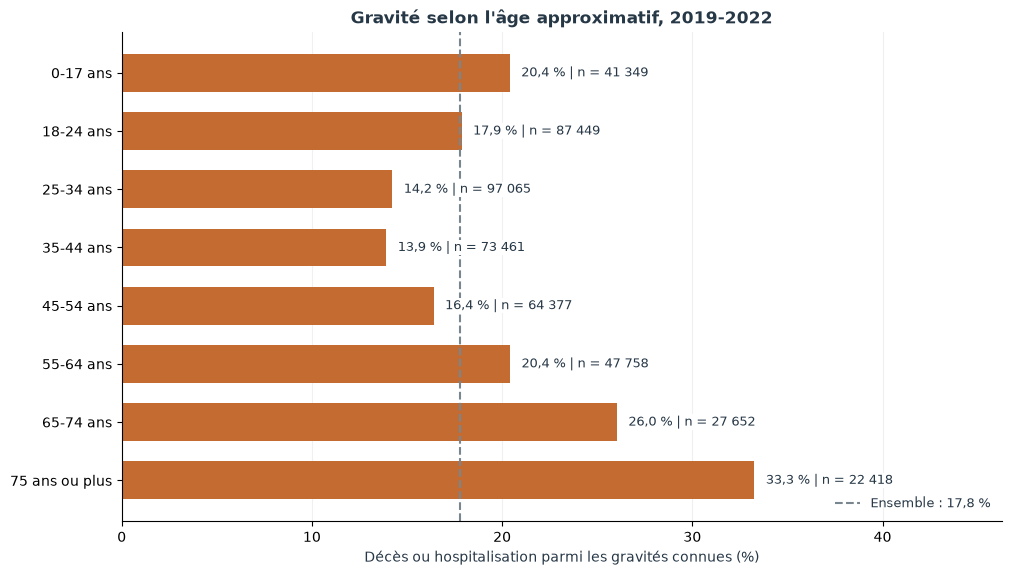

In [28]:
AGE_LABELS = ["0-17 ans", "18-24 ans", "25-34 ans", "35-44 ans", "45-54 ans", "55-64 ans", "65-74 ans", "75 ans ou plus"]
data["tranche_age"] = pd.cut(data["age_approx"], bins=[0, 18, 25, 35, 45, 55, 65, 75, 111],
                              right=False, labels=AGE_LABELS).astype("string").fillna("Âge inconnu")
age_comparison = describe_groups(data, "tranche_age", order=AGE_LABELS + ["Âge inconnu"])
display(age_comparison.round({"proportion_positive_pct": 2}))
plot_group_rates(age_comparison, "Gravité selon l'âge approximatif, 2019-2022", "04_05_gravite_selon_age.png")


La proportion atteint environ **33,3 % chez les 75 ans ou plus**, contre 13,9 % chez les
35-44 ans. La relation n'est pas simplement croissante sur toute la distribution : les
0-17 ans présentent également une proportion plus élevée que plusieurs groupes d'adultes.

Ce sont des comparaisons brutes. Les catégories d'usagers, les véhicules impliqués et le
contexte routier peuvent différer selon l'âge. Nous ne pouvons pas attribuer l'écart à
l'âge seul à partir de ce graphique.

**L'âge inconnu mérite une lecture distincte.** Sur 5 550 gravités connues dans ce groupe,
seules 10 correspondent à un décès ou une hospitalisation. Ce résultat très différent
invite à examiner les pratiques de saisie et les profils enregistrés, plutôt qu'à traiter
« âge inconnu » comme une tranche d'âge ordinaire. La documentation mentionne notamment
la création de conducteurs virtuels dans certaines situations de fuite ; elle ne permet
pas d'attribuer automatiquement tous les âges manquants à cette situation.


### 4.2 Les catégories d'usagers présentent-elles la même répartition ?

Nous comparons ici des proportions au sein de chaque catégorie, et non la part de chaque
catégorie parmi les victimes. Ces deux questions ont des dénominateurs différents.


,usagers_total,cible_connue,cible_inconnue,deces_ou_hospitalisation,proportion_positive_pct
categorie_usager,,,,,
Conducteur,348230,347962,268,57674,16.57
Passager,82592,82591,1,13498,16.34
Piéton,36526,36526,0,11909,32.6


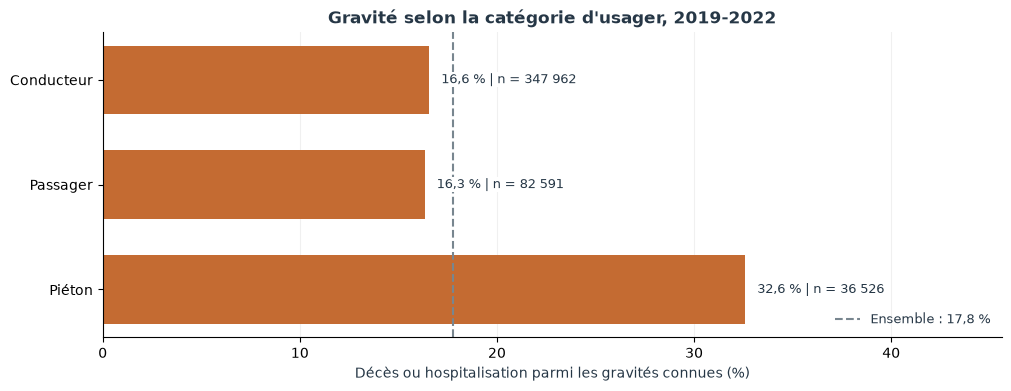

In [29]:
category_comparison = describe_groups(data, "categorie_usager", order=category_order)
display(category_comparison.round({"proportion_positive_pct": 2}))
plot_group_rates(category_comparison, "Gravité selon la catégorie d'usager, 2019-2022", "04_06_gravite_selon_categorie.png")


La proportion de décès ou d'hospitalisations est d'environ **32,6 % parmi les piétons**,
contre 16,6 % chez les conducteurs et 16,3 % chez les passagers. Les conducteurs représentent
pourtant le plus grand nombre absolu de cas positifs, en raison de leur effectif beaucoup
plus élevé dans les fichiers.

Ces résultats portent sur les usagers impliqués dans des accidents corporels enregistrés.
Ils ne permettent pas de comparer la dangerosité d'un mode de déplacement par trajet.
L'âge, le véhicule associé et le contexte devront être examinés ensemble dans la suite.


### 4.3 Les conditions de lumière sont-elles associées à des proportions différentes ?

Les cinq modalités de `lum` décrivent l'éclairage au moment de l'accident. Elles ne forment
pas une échelle numérique : nous comparons leurs proportions avec leurs libellés.


,usagers_total,cible_connue,cible_inconnue,deces_ou_hospitalisation,proportion_positive_pct
lumiere,,,,,
Plein jour,316212,316041,171,53546,16.94
Crépuscule ou aube,30207,30196,11,6082,20.14
Nuit sans éclairage public,45423,45404,19,13072,28.79
"Nuit, éclairage public éteint",3873,3872,1,758,19.58
"Nuit, éclairage public allumé",71623,71557,66,9622,13.45
Non renseigné,10,9,1,1,11.11


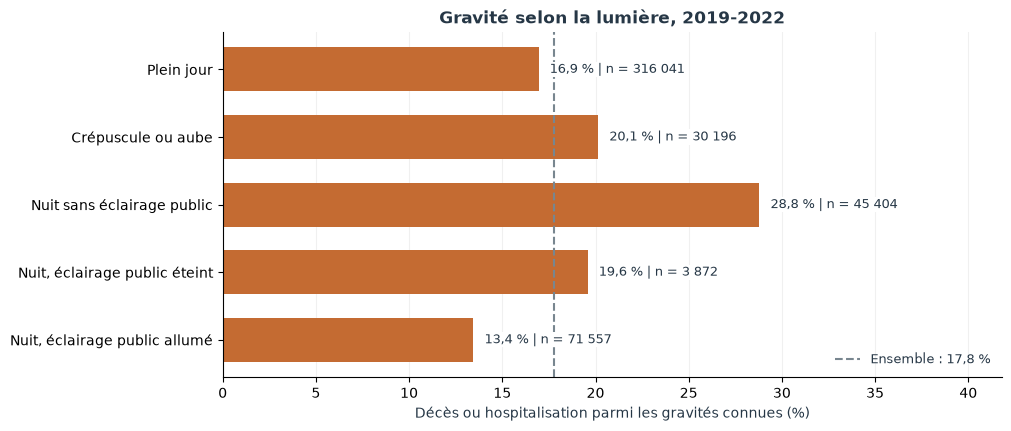

In [30]:
light_comparison = describe_groups(data, "lumiere", order=list(LUM_LABELS.values()) + [MISSING])
display(light_comparison.round({"proportion_positive_pct": 2}))
plot_group_rates(light_comparison, "Gravité selon la lumière, 2019-2022", "04_07_gravite_selon_lumiere.png")


La modalité **« nuit sans éclairage public »** présente une proportion d'environ **28,8 %**,
contre 16,9 % en plein jour. Les modalités nocturnes ne donnent pas toutes le même résultat :
la proportion est d'environ 13,4 % lorsque l'éclairage public est allumé.

Le graphique ne mesure pas l'effet causal de l'éclairage. Les routes, les vitesses autorisées,
les usagers et les horaires peuvent différer entre ces situations. Une comparaison croisée
avec l'agglomération sera notamment utile.

La lumière manque pour 10 usagers, dont 9 à gravité connue. Cet effectif est trop faible
pour interpréter sa proportion comme un profil comparable aux modalités renseignées.


### 4.4 Les contextes en et hors agglomération diffèrent-ils ?

`agg` distingue les accidents en agglomération de ceux survenus hors agglomération. Le
numérateur reste le nombre d'usagers avec cible 1 et le dénominateur les usagers du même
contexte dont la gravité est connue.


,usagers_total,cible_connue,cible_inconnue,deces_ou_hospitalisation,proportion_positive_pct
agglomeration,,,,,
Hors agglomération,175902,175858,44,45555,25.9
En agglomération,291446,291221,225,37526,12.89


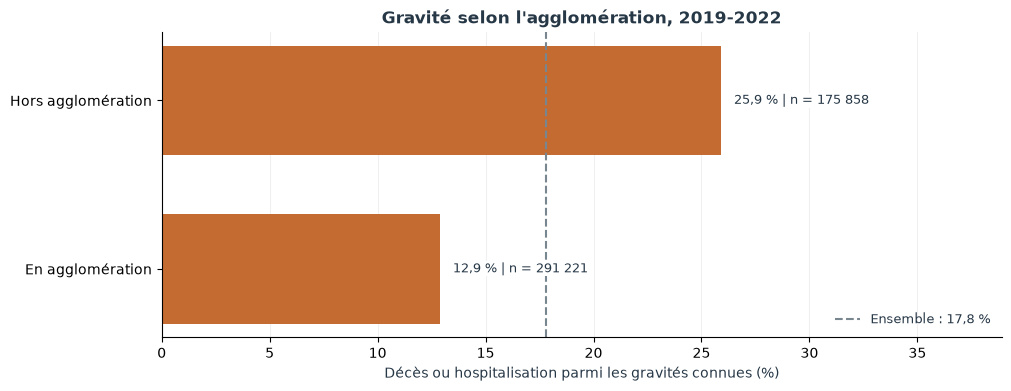

In [31]:
agglomeration_comparison = describe_groups(data, "agglomeration", order=list(AGG_LABELS.values()) + [MISSING])
display(agglomeration_comparison.round({"proportion_positive_pct": 2}))
plot_group_rates(agglomeration_comparison, "Gravité selon l'agglomération, 2019-2022", "04_08_gravite_selon_agglomeration.png")


La proportion est d'environ **25,9 % hors agglomération**, contre **12,9 % en agglomération**.
L'écart descriptif est donc d'environ 13 points de pourcentage. Le nombre total d'usagers
enregistrés est cependant plus élevé en agglomération.

Cette association doit être approfondie en tenant compte de la composition des groupes.
Elle ne permet pas de conclure que déplacer un même trajet hors agglomération multiplierait
sa probabilité de décès ou d'hospitalisation par un facteur donné.


### Relire les comparaisons par année

Les tableaux précédents regroupent quatre années dont les effectifs diffèrent. Nous
calculons aussi les proportions séparément par année, avec les mêmes dénominateurs.
Le tableau affiché ci-dessous reprend la catégorie d'usager et l'agglomération ; l'export
détaillé comprend également l'âge et la lumière, avec leurs effectifs.


In [32]:
comparison_specifications = {
    "âge": ("tranche_age", AGE_LABELS + ["Âge inconnu"]),
    "catégorie_usager": ("categorie_usager", category_order),
    "lumière": ("lumiere", list(LUM_LABELS.values()) + [MISSING]),
    "agglomération": ("agglomeration", list(AGG_LABELS.values()) + [MISSING]),
}
annual_comparison_parts = []
for year in TRAIN_YEARS:
    frame = data.loc[data["annee_source"].eq(year)]
    for name, (column, order) in comparison_specifications.items():
        table = describe_groups(frame, column, order).rename_axis("groupe").reset_index()
        table["dimension"] = name
        table["année"] = year
        annual_comparison_parts.append(table)
annual_comparisons = pd.concat(annual_comparison_parts, ignore_index=True)
annual_display = annual_comparisons.loc[
    annual_comparisons["dimension"].isin(["catégorie_usager", "agglomération"])
].pivot(index=["dimension", "groupe"], columns="année", values="proportion_positive_pct")
display(annual_display.round(2))


année                                 2019   2020   2021   2022
dimension        groupe                                        
agglomération    En agglomération    13.17  13.48  12.31  12.68
                 Hors agglomération  26.25  26.42   25.0  26.02
catégorie_usager Conducteur          16.78  17.09  15.85  16.68
                 Passager            16.35  16.45  15.93  16.66
                 Piéton              33.16   33.8  31.68  31.84

Cette lecture annuelle aide à repérer les comparaisons qui pourraient être influencées
par le poids d'un millésime. Elle ne constitue pas un ajustement statistique. La composition
par âge, catégorie d'usager et contexte peut encore différer au sein de chaque année.

Nous avons choisi les variables de cette exploration pour leur sens et leur présence dans
le projet. Les graphiques ne servent pas à retenir automatiquement les seules variables
qui présentent les écarts les plus visibles.


## 5. Vérifier les dénominateurs et enregistrer les résultats

Chaque comparaison doit retrouver tous les usagers, y compris les informations inconnues.
Les sommes des gravités connues et des cas positifs doivent également correspondre au
bilan général. Nous contrôlons enfin que les données de validation et de test n'ont pas
rejoint la table exploratoire.


In [33]:
comparison_tables = {
    "age": age_comparison, "categorie": category_comparison,
    "lumiere": light_comparison, "agglomeration": agglomeration_comparison,
}
for name, table in comparison_tables.items():
    assert int(table["usagers_total"].sum()) == len(data), name
    assert int(table["cible_connue"].sum()) == int(data[TARGET].notna().sum()), name
    assert int(table["cible_inconnue"].sum()) == int(data[TARGET].isna().sum()), name
    assert int(table["deces_ou_hospitalisation"].sum()) == int(data[TARGET].sum()), name
    assert table["proportion_positive_pct"].dropna().between(0, 100).all(), name
assert set(data["annee_source"]) == set(TRAIN_YEARS)
assert data["role_temporel"].eq("apprentissage").all()
assert int(severity_population["usagers"].sum()) == len(data)
assert int(annual_population["usagers"].sum()) == len(data)
assert int(annual_population["accidents"].sum()) == int(loading_check["accidents_distincts"])
assert len(data) == int(previous_train["usagers_métropole"].sum())
assert file_sha256(DATA_PATH) == input_sha256
print("Contrôles validés : effectifs, dénominateurs, proportions, période et fichier préparé inchangé.")


Contrôles validés : effectifs, dénominateurs, proportions, période et fichier préparé inchangé.


In [34]:
export_tables = {
    "population_annuelle": annual_population,
    "population_categories": category_population,
    "population_gravite": severity_population,
    "population_cible": target_population.set_index("groupe"),
    "statistiques_age": age_summary,
    **{f"gravite_selon_{name}": table for name, table in comparison_tables.items()},
    "comparaisons_annuelles": annual_comparisons.set_index(["dimension", "groupe", "année"]),
}
if EXPORT_RESULTS:
    for name, table in export_tables.items():
        table.to_csv(TABLE_DIR / f"04_{name}.csv", index=True, encoding="utf-8", na_rep=schema["marqueur_na_csv"])
    exploration_metadata = {
        "notebook": "04_exploratory_data_analysis.ipynb", "période_explorée": TRAIN_YEARS,
        "population": "usagers impliqués dans des accidents corporels enregistrés en métropole, Corse comprise",
        "unité": "usager source", "fichier_préparé": DATA_PATH.relative_to(PROJECT_ROOT).as_posix(),
        "sha256_fichier_préparé": input_sha256,
        "python": platform.python_version(), "pandas": pd.__version__, "matplotlib": matplotlib.__version__,
        "cible": "décès ou hospitalisation : grav 2 ou 3 ; grav inconnue exclue du dénominateur des proportions positives",
        "bornes_age": [0, 18, 25, 35, 45, 55, 65, 75, 111], "bornes_age_droite_exclue": True,
        "proportion_positive_globale_pct": global_rate,
        "catégories_inconnues": "conservées dans les tableaux, exclues des graphiques de comparaison des modalités renseignées",
        "lignes": len(data), "cibles_connues": int(data[TARGET].notna().sum()),
        "cibles_inconnues": int(data[TARGET].isna().sum()),
        "figures": figure_names, "tableaux": [f"04_{name}.csv" for name in export_tables],
        "limites": ["comparaisons descriptives non causales", "absence de données d'exposition",
                    "dépendance entre usagers d'un même accident", "hospitalisation : limites de collecte",
                    "âge inconnu associé à un profil de gravité différent", "2024 déjà examiné dans les audits précédents"],
    }
    (TABLE_DIR / "04_metadonnees_exploration.json").write_text(
        json.dumps(exploration_metadata, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
    print(f"{len(export_tables)} tableaux écrits dans reports/tables/ ; {len(figure_names)} figures dans reports/figures/.")
else:
    print("Export désactivé : les tableaux et graphiques restent disponibles dans le notebook.")


10 tableaux écrits dans reports/tables/ ; 8 figures dans reports/figures/.


## 6. Ce que nous retenons et ce que nous allons approfondir

Cette exploration met en évidence plusieurs différences descriptives :

- Les conducteurs sont les plus nombreux dans les fichiers, tandis que les piétons présentent
  une proportion de décès ou d'hospitalisations plus élevée parmi les gravités connues.
- Les proportions varient selon l'âge et sont particulièrement élevées chez les 75 ans ou plus.
  La relation observée ne se résume pas à une progression régulière avec l'âge.
- La nuit sans éclairage public et les accidents hors agglomération présentent des proportions
  plus élevées dans ces données. Leurs contextes et leurs populations peuvent se recouper.
- L'âge inconnu est associé à un profil très différent. Il faudra comprendre cette absence
  d'information avant de décider comment la représenter dans un modèle.
- Les effectifs annuels et les pratiques de collecte demandent de conserver une lecture temporelle.

**Ces constats ne prouvent pas que chaque caractéristique explique à elle seule les écarts.**
Ils orientent les questions du notebook suivant : les différences persistent-elles après
prise en compte d'autres caractéristiques ? Comment quantifier les écarts et leur incertitude
en tenant compte des accidents partagés ? Les conclusions changent-elles lorsqu'on étudie
les décès séparément ?

`vma` sera étudiée dans un volet distinct, avec une règle explicite pour les limitations
suspectes et les désaccords entre lieux. Les variables non explorées ici restent disponibles
dans la table préparée. Le choix des variables du modèle sera documenté avant l'évaluation.

La prochaine étape est donc de **définir le notebook 5 d'analyse statistique et probabiliste**,
avant d'en écrire le code.
